# 케이스별 monitor.csv 데이터 묶음

경로 리스트를 넣으면 `cases[이름]` = 구조화 배열(필드: `step, t, dt, div, Theta_c, Nu`) 묶음을 만든다.

- 경로는 런 디렉터리(`../e18_buoyfix_equil`) 또는 `monitor.csv` 파일 자체 둘 다 가능
- 재시작으로 step이 겹치면 마지막 기록만 남기고 step 순으로 정렬
- `Theta_c == 0` 구간은 stats 창이 아직 시작 안 된 구간 (필터는 시각화 쪽에서)

사용 예: `cases['e18_buoyfix_equil']['t']`, `cases['e18_buoyfix_equil']['Theta_c']`

In [3]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

def load_cases(paths, names=None):
    """paths: 런 디렉터리 또는 monitor.csv 경로 리스트.
    names: 각 경로에 붙일 이름 리스트(생략하면 디렉터리 이름).
    반환: {이름: 구조화 배열(step, t, dt, div, Theta_c, Nu)}"""
    cases = {}
    for i, p in enumerate(paths):
        p = Path(p)
        csv = p if p.suffix == '.csv' else p / 'monitor.csv'
        name = names[i] if names else (csv.parent.name if csv.parent.name != '.' else csv.stem)
        if not csv.exists():
            print(f'[skip] {csv} 없음')
            continue
        data = np.genfromtxt(csv, delimiter=',', names=True)
        data = data[np.argsort(data['step'], kind='stable')]
        keep = np.append(data['step'][1:] != data['step'][:-1], True)  # 겹친 step은 마지막 기록만
        data = data[keep]
        cases[name] = data
        print(f"{name:40s} rows={len(data):>7}  "
              f"step {data['step'][0]:.0f}..{data['step'][-1]:.0f}  "
              f"t {data['t'][0]:.1f}..{data['t'][-1]:.1f}  "
              f"Theta_c(last)={data['Theta_c'][-1]:.4f}")
    return cases

# Theta_c 유효 구간만 보려면: d = cases[name]; d = d[d['Theta_c'] != 0]
PaScaL_data = np.genfromtxt("PaScaL_TCS.csv", delimiter=",", comments="#")
Horm_data = np.genfromtxt("Horm.csv", delimiter=",", comments="#")
zhang_data = np.genfromtxt("zhang.csv", delimiter=",", comments="#")

gh200_deltat40_256_cfl1_theta1           rows=    199  step 100..19900  t 2.3..64.1  Theta_c(last)=0.0675
Target_Theta = 40


Text(0, 0.5, '$\\theta_c$')

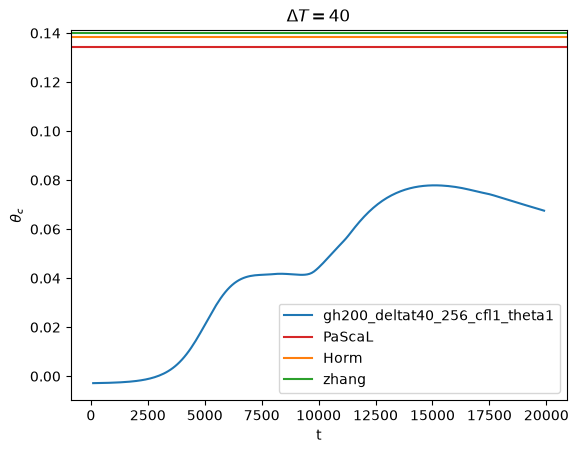

In [4]:
paths = [
    "../gh200_deltat40_256_cfl1_theta1",
]
names = [
    "gh200_deltat40_256_cfl1_theta1",
]
target = [
    40,
]

cases = load_cases(paths, names)

for i in range(len(paths)):

    plt.plot(cases[names[i]]["step"], cases[names[i]]["Theta_c"], label=names[i], color="tab:blue")

print("Target_Theta =", target[0])
PaScaL_ref = np.interp(target[0], PaScaL_data[:, 0], PaScaL_data[:, 1])
Horm_ref = np.interp(target[0], Horm_data[:, 0], Horm_data[:, 1])
zhang_ref = np.interp(target[0], zhang_data[:, 0], zhang_data[:, 1])
plt.axhline(y=PaScaL_ref/target[0], color="tab:red", label="PaScaL")
plt.axhline(y=Horm_ref/target[0], color="tab:orange", label="Horm")
plt.axhline(y=zhang_ref/target[0], color="tab:green", label="zhang")
plt.legend()

plt.title(r"$\Delta{T} =$" + f"{target[0]}")
plt.xlabel("t")
plt.ylabel(r"$\theta_c$")
# plt.xlim(0, 8000)